# Module 4 & Module 5 — Vérification par référence & Décision qualité

Ce notebook intègre directement les **Modules 1, 2 et 3** pour exécuter la fin du pipeline d'inspection visuelle :
- **Module 1** : Détection & Segmentation d'instance (`YOLOv8-Seg` — poids `wiring_harness_connectors_seg/weights/best.pt`)
- **Module 2** : Mesure géométrique & topologique via `HarnessInspector` (`module2_yolo_inspector.py` : squelettisation, longueur, extrémités, intersections)
- **Module 3** : Orientation des composants (`YOLO-OBB` — poids `03_orientation_des_composants/weights/best.pt`)
- **Module 4** : Alignement d'image (*ORB + RANSAC*) et appariement (*Hungarian / Graph Matching*)
- **Module 5** : Règles géométriques, décision qualité (**CONFORME** / **NON CONFORME**), visualisation et export JSON/CSV.

## Bloc 1 — Configuration des chemins, modèles (Modules 1, 2 & 3) et tolérances

In [2]:
import importlib.util
import sys
from pathlib import Path

MODULE2_PATH = Path(r"D:\S5\Projet_d_expertise\projet\src\module2_yolo_inspector.py").resolve()

if not MODULE2_PATH.exists():
    raise FileNotFoundError(f"Fichier introuvable : {MODULE2_PATH}")

if str(MODULE2_PATH.parent) not in sys.path:
    sys.path.insert(0, str(MODULE2_PATH.parent))

spec = importlib.util.spec_from_file_location("module2_yolo_inspector", MODULE2_PATH)
module2_yolo_inspector = importlib.util.module_from_spec(spec)
sys.modules["module2_yolo_inspector"] = module2_yolo_inspector
spec.loader.exec_module(module2_yolo_inspector)

# Récupération de la classe du module 2 (ex. HarnessInspector)
HarnessInspector = module2_yolo_inspector.HarnessInspector

c:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
c:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
c:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


In [3]:
import sys
import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO
# Ajout du dossier courant/parent au PYTHONPATH pour importer module2_yolo_inspector.py
for candidate in [Path.cwd(), Path.cwd().parent]:
    if (candidate / "module2_yolo_inspector.py").exists() and str(candidate) not in sys.path:
        sys.path.insert(0, str(candidate))

from module2_yolo_inspector import HarnessInspector

# -------------------------------------------------------------------------
# 1. Images : Référence (conforme) vs Image à tester
# Laissez None pour ouvrir la boîte de dialogue de sélection Windows
# -------------------------------------------------------------------------
REF_IMAGE_PATH = None   # Ex: r"D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\test\images\ref.jpg"
TEST_IMAGE_PATH = None  # Ex: r"D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\test\images\test.jpg"

# -------------------------------------------------------------------------
# 2. Chemins vers les modèles entraînés (Modules 1/2 et Module 3)
# -------------------------------------------------------------------------
MODELS_DIR = Path(r"D:\S5\Projet_d_expertise\projet\models").resolve()

# Modèle Module 1 (YOLOv8-Seg utilisé par Module 2)
MODEL_SEG_PATH = MODELS_DIR / "01_detection_et_segmentation_paliers" / "best_ep100.pt"
FALLBACK_SEG_DIR = MODELS_DIR

# Modèle Module 3 (YOLO-OBB pour l'orientation)
MODEL_OBB_PATH = MODELS_DIR / "03_orientation_des_composants_paliers"  / "best_ep100.pt"

# -------------------------------------------------------------------------
# 3. Paramètres d'inférence & Tolérances qualité (Module 5)
# -------------------------------------------------------------------------
CONF_THRESHOLD = 0.25
IMG_SIZE = 640

TOL_POSITION_PX = 40.0       # Écart maximal de position autorisé (en pixels après alignement)
TOL_ANGLE_DEG = 10.0         # Écart maximal d'orientation autorisé (en degrés)
TOL_LENGTH_RATIO = 0.15      # Écart maximal relatif sur la longueur totale du squelette (15 %)
MAX_MATCH_DIST_PX = 100.0    # Distance maximale pour apparier un composant test avec la référence

def pick_image_dialog(title: str) -> Path:
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)
    selected = filedialog.askopenfilename(
        title=title,
        filetypes=[("Images", "*.jpg *.jpeg *.png *.bmp *.webp"), ("Tous les fichiers", "*.*")]
    )
    root.destroy()
    if not selected:
        raise ValueError(f"Sélection annulée pour : {title}")
    return Path(selected).resolve()

ref_path = Path(REF_IMAGE_PATH).resolve() if REF_IMAGE_PATH else pick_image_dialog("1/2 - Choisissez l'IMAGE DE RÉFÉRENCE (conforme)")
test_path = Path(TEST_IMAGE_PATH).resolve() if TEST_IMAGE_PATH else pick_image_dialog("2/2 - Choisissez l'IMAGE À TESTER")

if not MODEL_OBB_PATH.exists():
    raise FileNotFoundError(f"Modèle OBB (Module 3) introuvable : {MODEL_OBB_PATH}")

print("Image de référence :", ref_path)
print("Image à tester     :", test_path)
print("Modèle Seg (Mod 1) :", MODEL_SEG_PATH)
print("Modèle OBB (Mod 3) :", MODEL_OBB_PATH)

Image de référence : D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8-obb\train\images\7_jpg.rf.6d4eadcaf073c7749402e66daee011bd.jpg
Image à tester     : D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8-obb\train\images\11_jpg.rf.d3942cde8e4f703c0ed75d0e63c03ef4.jpg
Modèle Seg (Mod 1) : D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation_paliers\best_ep100.pt
Modèle OBB (Mod 3) : D:\S5\Projet_d_expertise\projet\models\03_orientation_des_composants_paliers\best_ep100.pt


## Bloc 2 — Exécution des Modules 1, 2 et 3 sur la Référence et le Test

In [4]:
# Initialisation du Module 2 (encapsule le modèle de segmentation du Module 1)
inspector_mod12 = HarnessInspector(
    model_path=MODEL_SEG_PATH,
    fallback_dir=FALLBACK_SEG_DIR,
    conf_threshold=CONF_THRESHOLD,
    img_size=IMG_SIZE,
)

# Initialisation du modèle OBB du Module 3
model_obb_mod3 = YOLO(str(MODEL_OBB_PATH))

def normalize_angle_deg(angle_deg: float) -> float:
    while angle_deg > 90.0:
        angle_deg -= 180.0
    while angle_deg < -90.0:
        angle_deg += 180.0
    return float(angle_deg)

def run_modules_1_2_3(image_path: Path) -> dict:
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
        raise FileNotFoundError(f"Impossible de lire l'image : {image_path}")

    # --- MODULES 1 & 2 : Segmentation + Mesure géométrique (HarnessInspector) ---
    df_seg_geom, vis_seg_skel = inspector_mod12.predict(
        image_source=img_bgr,
        conf=CONF_THRESHOLD,
        show_plot=False,
    )

    total_length_px = int(df_seg_geom["longueur_px"].sum()) if not df_seg_geom.empty else 0
    total_endpoints = int(df_seg_geom["extremites"].sum()) if not df_seg_geom.empty else 0
    total_junctions = int(df_seg_geom["intersections"].sum()) if not df_seg_geom.empty else 0

    # --- MODULE 3 : Orientation des composants (YOLO-OBB) ---
    res_obb = model_obb_mod3.predict(
        source=img_bgr, conf=CONF_THRESHOLD, imgsz=IMG_SIZE, verbose=False
    )[0]

    obb_components = []
    if getattr(res_obb, "obb", None) is not None and len(res_obb.obb) > 0:
        xywhr = res_obb.obb.xywhr.cpu().numpy()
        cls_ids = res_obb.obb.cls.cpu().numpy().astype(int)
        confs = res_obb.obb.conf.cpu().numpy()
        for i, (cx, cy, bw, bh, ang_rad) in enumerate(xywhr):
            cid = int(cls_ids[i])
            cname = model_obb_mod3.names.get(cid, str(cid))
            obb_components.append({
                "id": i,
                "class_id": cid,
                "class_name": cname,
                "conf": float(confs[i]),
                "center_xy": (float(cx), float(cy)),
                "size_wh": (float(bw), float(bh)),
                "angle_deg": normalize_angle_deg(float(np.degrees(ang_rad))),
            })

    return {
        "path": image_path,
        "image_bgr": img_bgr,
        "df_seg_geom": df_seg_geom,
        "vis_seg_skel": vis_seg_skel,
        "vis_obb": res_obb.plot(),
        "obb_components": obb_components,
        "topology": {
            "total_length_px": total_length_px,
            "total_endpoints": total_endpoints,
            "total_junctions": total_junctions,
        },
    }

ref_data = run_modules_1_2_3(ref_path)
test_data = run_modules_1_2_3(test_path)

print(f"Référence -> OBB: {len(ref_data['obb_components'])} | Seg: {len(ref_data['df_seg_geom'])} | Longueur squelette: {ref_data['topology']['total_length_px']} px | Intersections: {ref_data['topology']['total_junctions']}")
print(f"Test      -> OBB: {len(test_data['obb_components'])} | Seg: {len(test_data['df_seg_geom'])} | Longueur squelette: {test_data['topology']['total_length_px']} px | Intersections: {test_data['topology']['total_junctions']}")

display(ref_data["df_seg_geom"])
display(test_data["df_seg_geom"])

Référence -> OBB: 2 | Seg: 3 | Longueur squelette: 1181 px | Intersections: 7
Test      -> OBB: 12 | Seg: 13 | Longueur squelette: 3071 px | Intersections: 36


,id,classe,confiance,bbox_xyxy,longueur_px,extremites,intersections
0,0,connector,0.945,"[281.6, 348.7, 462.7, 594.1]",352,4,2
1,1,connector,0.915,"[365.0, 159.6, 516.3, 327.0]",285,4,2
2,2,connector,0.682,"[103.5, 151.9, 279.2, 465.8]",544,4,3


,id,classe,confiance,bbox_xyxy,longueur_px,extremites,intersections
0,0,connector,0.964,"[253.7, 195.0, 364.1, 386.3]",293,8,2
1,1,connector,0.953,"[187.5, 5.1, 274.8, 151.9]",156,4,2
2,2,connector,0.935,"[345.4, 456.1, 449.4, 639.6]",219,6,1
3,3,connector,0.917,"[297.4, 34.5, 355.4, 147.3]",115,3,1
4,4,connector,0.917,"[35.9, 427.5, 117.1, 594.3]",166,4,2
5,5,connector,0.909,"[379.1, 166.9, 479.9, 368.2]",261,5,3
6,6,connector,0.908,"[448.8, 521.7, 540.4, 639.0]",162,3,1
7,7,connector,0.907,"[183.5, 395.6, 290.6, 577.0]",242,6,3
8,8,connector,0.864,"[437.0, 0.0, 485.8, 68.5]",82,3,1
9,9,connector,0.857,"[112.9, 278.0, 222.3, 451.6]",206,5,1


## Bloc 3 — Module 4 : Vérification par référence (*Image Registration* & *Graph Matching*)

In [5]:
def align_test_to_reference(img_test_bgr: np.ndarray, img_ref_bgr: np.ndarray):
    """Recalage géométrique (ORB + RANSAC) de l'image testée vers le repère de référence."""
    g_test = cv2.cvtColor(img_test_bgr, cv2.COLOR_BGR2GRAY)
    g_ref = cv2.cvtColor(img_ref_bgr, cv2.COLOR_BGR2GRAY)

    orb = cv2.ORB_create(nfeatures=2500)
    kp1, des1 = orb.detectAndCompute(g_test, None)
    kp2, des2 = orb.detectAndCompute(g_ref, None)

    identity = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]], dtype=np.float64)
    if des1 is None or des2 is None or len(kp1) < 10 or len(kp2) < 10:
        return identity, 0.0, 0

    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
    matches = sorted(bf.match(des1, des2), key=lambda m: m.distance)[:250]
    if len(matches) < 6:
        return identity, 0.0, len(matches)

    pts_test = np.float32([kp1[m.queryIdx].pt for m in matches])
    pts_ref = np.float32([kp2[m.trainIdx].pt for m in matches])

    M, inliers = cv2.estimateAffinePartial2D(pts_test, pts_ref, method=cv2.RANSAC, ransacReprojThreshold=5.0)
    if M is None:
        return identity, 0.0, 0

    n_inliers = int(inliers.sum()) if inliers is not None else 0
    global_rot_deg = float(np.degrees(np.arctan2(M[1, 0], M[0, 0])))
    return M, global_rot_deg, n_inliers

def project_xy(pt_xy, M):
    vec = np.array([pt_xy[0], pt_xy[1], 1.0], dtype=np.float64)
    res = M @ vec
    return (float(res[0]), float(res[1]))

def angular_error_deg(a_test: float, a_ref: float, symmetric_180: bool = True) -> float:
    diff = (a_test - a_ref + 180.0) % 360.0 - 180.0
    if symmetric_180:
        if diff > 90.0:
            diff -= 180.0
        elif diff < -90.0:
            diff += 180.0
    return abs(float(diff))

M_affine, global_rot_deg, n_inliers = align_test_to_reference(test_data["image_bgr"], ref_data["image_bgr"])
print(f"Alignement RANSAC : {n_inliers} inliers | Rotation globale caméra = {global_rot_deg:+.2f} deg")

# Appariement par classe entre référence et test
matched_rows = []
missing_items = []
extra_items = []

all_classes = sorted(
    set(c["class_name"] for c in ref_data["obb_components"]) |
    set(c["class_name"] for c in test_data["obb_components"])
)

for cname in all_classes:
    refs = [c for c in ref_data["obb_components"] if c["class_name"] == cname]
    tests = [c for c in test_data["obb_components"] if c["class_name"] == cname]

    if not refs:
        extra_items.extend(tests)
        continue
    if not tests:
        missing_items.extend(refs)
        continue

    proj_tests = [project_xy(t["center_xy"], M_affine) for t in tests]
    cost = np.zeros((len(refs), len(tests)), dtype=np.float64)
    for i, r in enumerate(refs):
        rx, ry = r["center_xy"]
        for j, (tx, ty) in enumerate(proj_tests):
            cost[i, j] = np.hypot(tx - rx, ty - ry)

    row_ind, col_ind = linear_sum_assignment(cost)
    used_r, used_t = set(), set()

    for i, j in zip(row_ind, col_ind):
        dist_px = float(cost[i, j])
        if dist_px <= MAX_MATCH_DIST_PX:
            used_r.add(i)
            used_t.add(j)
            r = refs[i]
            t = tests[j]
            aligned_angle = normalize_angle_deg(t["angle_deg"] + global_rot_deg)
            err_angle = angular_error_deg(aligned_angle, r["angle_deg"])
            matched_rows.append({
                "classe": cname,
                "ref_id": r["id"],
                "test_id": t["id"],
                "ref_xy": (round(r["center_xy"][0], 1), round(r["center_xy"][1], 1)),
                "test_aligned_xy": (round(proj_tests[j][0], 1), round(proj_tests[j][1], 1)),
                "ecart_pos_px": round(dist_px, 2),
                "angle_ref_deg": round(r["angle_deg"], 2),
                "angle_test_deg": round(aligned_angle, 2),
                "ecart_angle_deg": round(err_angle, 2),
            })

    for i, r in enumerate(refs):
        if i not in used_r:
            missing_items.append(r)
    for j, t in enumerate(tests):
        if j not in used_t:
            extra_items.append(t)

df_matched = pd.DataFrame(matched_rows)
display(df_matched)

Alignement RANSAC : 6 inliers | Rotation globale caméra = +140.29 deg


,classe,ref_id,test_id,ref_xy,test_aligned_xy,ecart_pos_px,angle_ref_deg,angle_test_deg,ecart_angle_deg
0,connector,0,0,"(440.0, 238.7)","(424.5, 238.5)",15.51,18.20,-13.04,31.24
1,connector,1,10,"(376.2, 481.0)","(419.8, 444.1)",57.16,15.19,-16.59,31.78


## Bloc 4 — Module 5 : Décision qualité (CONFORME / DÉFAUTS), Visualisation & Rapport

DÉCISION QUALITÉ (MODULE 5) : NON CONFORME
  1. Composant EN TROP / NON APPARIÉ : connector détecté à (316, 520)
  2. Composant EN TROP / NON APPARIÉ : connector détecté à (231, 86)
  3. Composant EN TROP / NON APPARIÉ : connector détecté à (326, 84)
  4. Composant EN TROP / NON APPARIÉ : connector détecté à (317, 285)
  5. Composant EN TROP / NON APPARIÉ : connector détecté à (73, 516)
  6. Composant EN TROP / NON APPARIÉ : connector détecté à (157, 365)
  7. Composant EN TROP / NON APPARIÉ : connector détecté à (509, 587)
  8. Composant EN TROP / NON APPARIÉ : connector détecté à (549, 392)
  9. Composant EN TROP / NON APPARIÉ : connector détecté à (401, 554)
  10. Composant EN TROP / NON APPARIÉ : connector détecté à (605, 542)
  11. Erreur orientation connector (#0) : 31.24 deg > 10.0 deg
  12. Décalage position connector (#1) : 57.16 px > 40.0 px
  13. Erreur orientation connector (#1) : 31.78 deg > 10.0 deg
  14. Longueur totale du squelette hors tolérance : 3071 px vs 1181 px (é

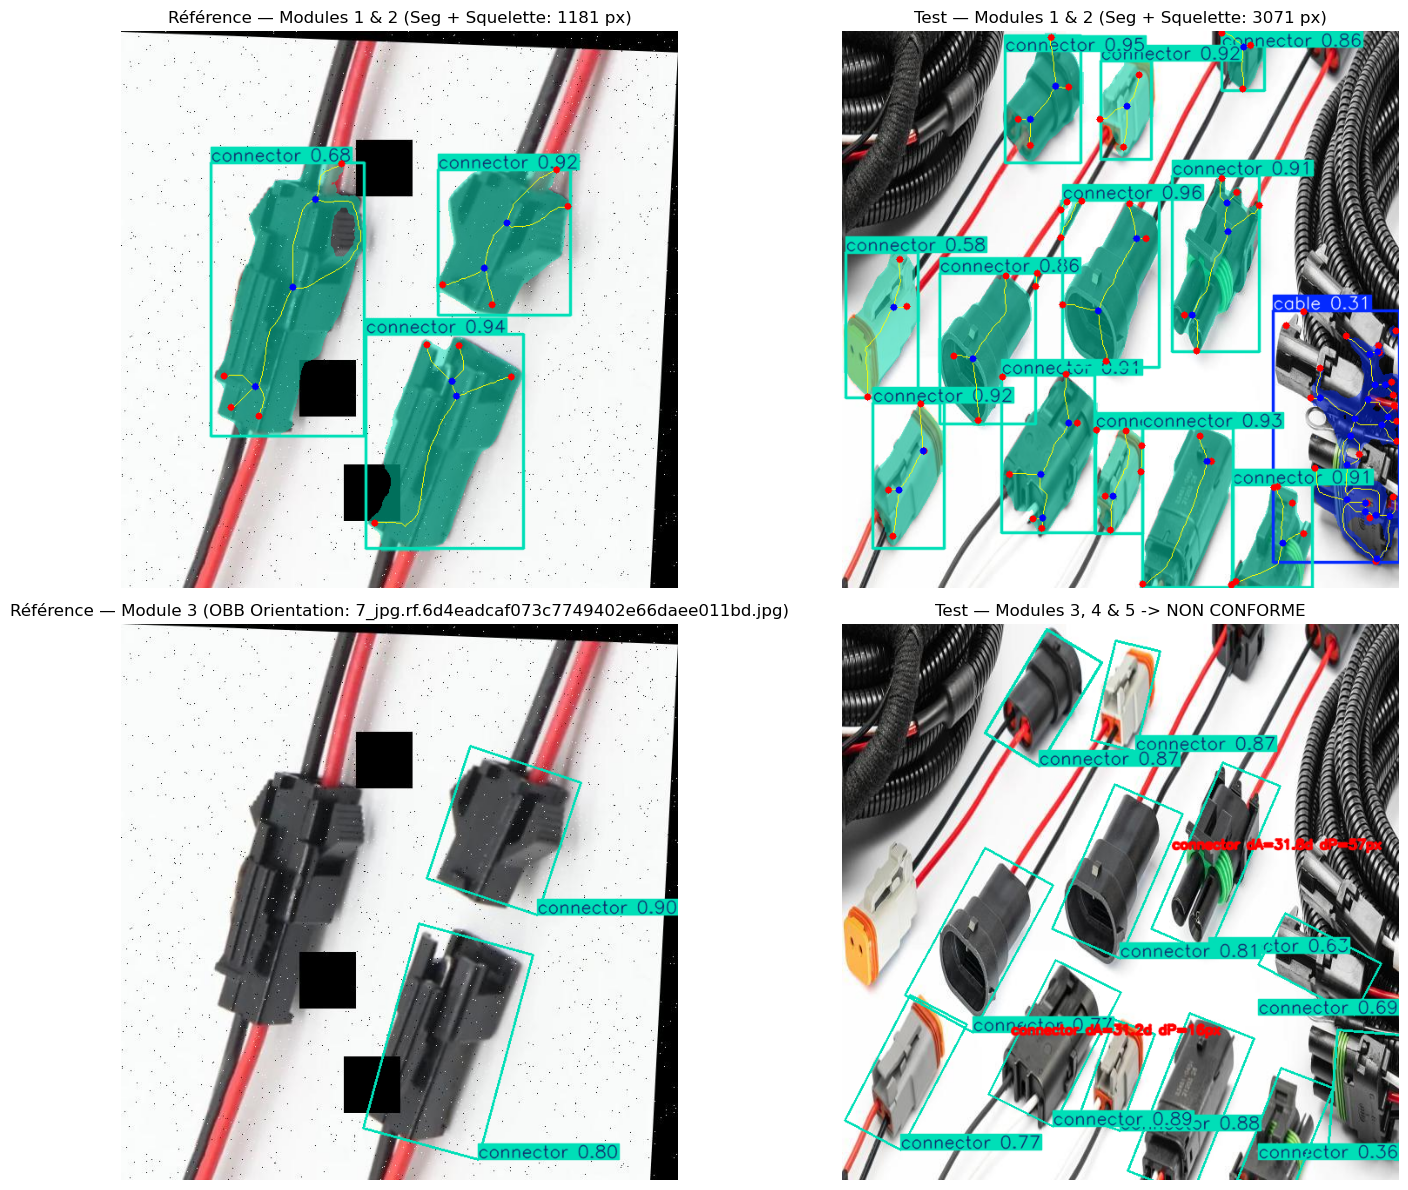

Rapport qualité enregistré : D:\S5\Projet_d_expertise\projet\reports\rapport_qualite_11_jpg.rf.d3942cde8e4f703c0ed75d0e63c03ef4.json


In [6]:
defects = []

# 1. Vérification des composants manquants ou en surplus (Module 3 + Module 4)
for m in missing_items:
    defects.append(f"Composant MANQUANT : {m['class_name']} attendu autour de ({m['center_xy'][0]:.0f}, {m['center_xy'][1]:.0f})")
for e in extra_items:
    defects.append(f"Composant EN TROP / NON APPARIÉ : {e['class_name']} détecté à ({e['center_xy'][0]:.0f}, {e['center_xy'][1]:.0f})")

# 2. Vérification des tolérances de position et d'orientation (Module 3 + Module 4)
if not df_matched.empty:
    status_list = []
    for _, row in df_matched.iterrows():
        item_issues = []
        if row["ecart_pos_px"] > TOL_POSITION_PX:
            msg = f"Décalage position {row['classe']} (#{row['ref_id']}) : {row['ecart_pos_px']} px > {TOL_POSITION_PX} px"
            defects.append(msg)
            item_issues.append("POSITION_HORS_TOL")
        if row["ecart_angle_deg"] > TOL_ANGLE_DEG:
            msg = f"Erreur orientation {row['classe']} (#{row['ref_id']}) : {row['ecart_angle_deg']} deg > {TOL_ANGLE_DEG} deg"
            defects.append(msg)
            item_issues.append("ANGLE_HORS_TOL")
        status_list.append("OK" if not item_issues else " | ".join(item_issues))
    df_matched["statut"] = status_list

# 3. Vérification géométrique & topologique du squelette (Module 1 + Module 2)
ref_len = ref_data["topology"]["total_length_px"]
test_len = test_data["topology"]["total_length_px"]
if ref_len > 0:
    len_ratio_err = abs(test_len - ref_len) / ref_len
    if len_ratio_err > TOL_LENGTH_RATIO:
        defects.append(
            f"Longueur totale du squelette hors tolérance : {test_len} px vs {ref_len} px (écart {len_ratio_err*100:.1f}% > {TOL_LENGTH_RATIO*100:.0f}%)"
        )

ref_junc = ref_data["topology"]["total_junctions"]
test_junc = test_data["topology"]["total_junctions"]
if test_junc != ref_junc:
    defects.append(f"Nombre d'intersections (branches) différent : {test_junc} détectée(s) vs {ref_junc} attendue(s)")

ref_end = ref_data["topology"]["total_endpoints"]
test_end = test_data["topology"]["total_endpoints"]
if test_end != ref_end:
    defects.append(f"Nombre d'extrémités différent : {test_end} détectée(s) vs {ref_end} attendue(s)")

# 4. Verdict final
verdict = "CONFORME" if len(defects) == 0 else "NON CONFORME"
print("====================================================")
print(f"DÉCISION QUALITÉ (MODULE 5) : {verdict}")
print("====================================================")
if defects:
    for idx_d, d in enumerate(defects, 1):
        print(f"  {idx_d}. {d}")
else:
    print("  Aucun défaut détecté. Toutes les mesures géométriques, positions et orientations sont conformes.")

# 5. Visualisation complète (2x2 : Segmentation/Squelette Mod 1-2 + Orientation/Comparaison Mod 3-4-5)
vis_test_comp = test_data["vis_obb"].copy()
if not df_matched.empty:
    for _, r in df_matched.iterrows():
        color = (0, 220, 0) if r["statut"] == "OK" else (0, 0, 255)
        label_txt = f"{r['classe']} dA={r['ecart_angle_deg']:.1f}d dP={r['ecart_pos_px']:.0f}px"
        raw_t = next((c for c in test_data["obb_components"] if c["id"] == r["test_id"]), None)
        if raw_t is not None:
            cx, cy = int(raw_t["center_xy"][0]), int(raw_t["center_xy"][1])
            cv2.putText(vis_test_comp, label_txt, (max(5, cx - 50), max(20, cy - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2, cv2.LINE_AA)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes[0, 0].imshow(cv2.cvtColor(ref_data["vis_seg_skel"], cv2.COLOR_BGR2RGB))
axes[0, 0].set_title(f"Référence — Modules 1 & 2 (Seg + Squelette: {ref_len} px)")
axes[0, 0].axis("off")

axes[0, 1].imshow(cv2.cvtColor(test_data["vis_seg_skel"], cv2.COLOR_BGR2RGB))
axes[0, 1].set_title(f"Test — Modules 1 & 2 (Seg + Squelette: {test_len} px)")
axes[0, 1].axis("off")

axes[1, 0].imshow(cv2.cvtColor(ref_data["vis_obb"], cv2.COLOR_BGR2RGB))
axes[1, 0].set_title(f"Référence — Module 3 (OBB Orientation: {ref_path.name})")
axes[1, 0].axis("off")

axes[1, 1].imshow(cv2.cvtColor(vis_test_comp, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title(f"Test — Modules 3, 4 & 5 -> {verdict}")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

# 6. Export du rapport qualité JSON et CSV
report_payload = {
    "verdict": verdict,
    "reference_image": str(ref_path),
    "test_image": str(test_path),
    "global_camera_rotation_deg": round(global_rot_deg, 3),
    "topology_reference": ref_data["topology"],
    "topology_test": test_data["topology"],
    "tolerances": {
        "position_px": TOL_POSITION_PX,
        "angle_deg": TOL_ANGLE_DEG,
        "length_ratio": TOL_LENGTH_RATIO,
    },
    "defects": defects,
    "matched_components": df_matched.to_dict(orient="records") if not df_matched.empty else [],
}

out_json = Path(f"rapport_qualite_{test_path.stem}.json").resolve()
out_json.write_text(json.dumps(report_payload, indent=2, ensure_ascii=False), encoding="utf-8")
if not df_matched.empty:
    df_matched.to_csv(Path(f"comparaison_{test_path.stem}.csv").resolve(), index=False, encoding="utf-8-sig")
print(f"Rapport qualité enregistré : {out_json}")